In [1]:
from tensorflow import keras # 匯入 TensorFlow 的 Keras 深度學習函式庫
from keras.models import Sequential # 匯入 Sequential 模型，用來依序堆疊神經網路層
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten # Dense：全連接層 # Conv2D：二維卷積層，用來擷取圖片特徵 # MaxPooling2D：池化層，用來縮小圖片尺寸 # Flatten：將多維資料攤平成一維
model=Sequential() # 建立一個空的 Sequential 神經網路模型
model.add(Conv2D(filters=16, kernel_size=(5, 5), input_shape=(28, 28, 1), activation='relu')) # 建立36個特徵過濾器 # kernel_size=(5,5)：使用5×5的卷積核 # input_shape=(28,28,1)：輸入圖片大小28×28，灰階圖片只有1個通道
model.add(MaxPooling2D(pool_size=(2, 2)))
#model.add(Conv2D(filters=36, kernel_size=(5, 5), activation='relu'))
#model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(10, activation='softmax')) # 共有10個神經元，代表數字0~9 # softmax可輸出各類別的機率
model.summary() # 顯示整個模型架構與參數數量
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy']) # loss：使用交叉熵損失函數 # metrics：以accuracy(正確率)作為評估指標

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,466 (91.66 KB)

 Trainable params: 23,466 (91.66 KB)

 Non-trainable params: 0 (0.00 B)

In [2]:
mnist=keras.datasets.mnist # 載入MNIST手寫數字資料集
(train_data, train_label), (test_data, test_label) = mnist.load_data() # 載入訓練資料與測試資料
test_label_original=test_label #for crosstab # 備份原始測試標籤，方便後續交叉分析(crosstab)
train_label = keras.utils.to_categorical(train_label) # 將訓練標籤轉換為 One-Hot Encoding
test_label = keras.utils.to_categorical(test_label) # 將測試標籤轉換為 One-Hot Encoding

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
train_history=model.fit(train_data,train_label,epochs=10,batch_size=512) # epochs=10：全部資料重複訓練10次 # batch_size=512：每次取512筆資料更新權重

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8312 - loss: 3.3542
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9606 - loss: 0.2508
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9736 - loss: 0.1198
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9819 - loss: 0.0706
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9857 - loss: 0.0502
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9887 - loss: 0.0381
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9912 - loss: 0.0289
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9928 - loss: 0.0233
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9938 - loss: 0.0192
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9944 - loss: 0.0169


In [4]:
score=model.evaluate(test_data, test_label) # 使用測試資料評估模型的效能
print(score[1]) # 印出模型的準確率(accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9767 - loss: 0.1337
0.9767000079154968


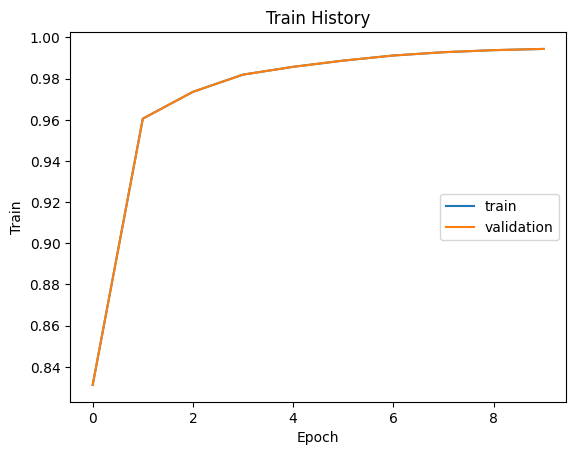

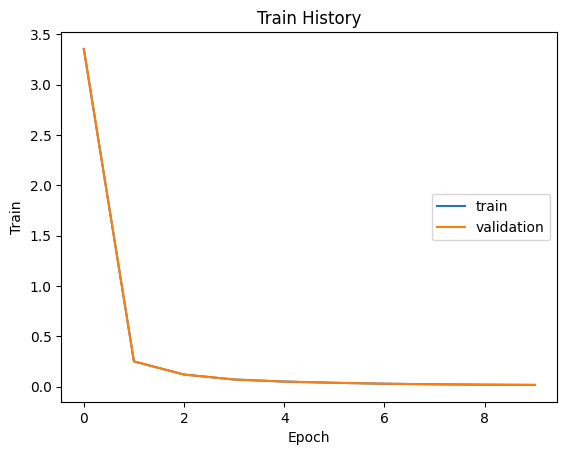

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(10000, 10)


predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,977,1,0,1,0,0,1,0,0,0
1,0,1130,1,1,2,0,0,1,0,0
2,2,25,984,8,0,0,3,10,0,0
3,0,0,0,1000,0,6,0,2,2,0
4,1,1,0,0,963,0,3,6,0,8
5,2,1,0,7,0,875,1,0,4,2
6,9,7,0,1,2,4,935,0,0,0
7,0,5,3,3,1,1,0,1008,2,5
8,17,5,1,10,4,8,3,4,917,5


In [5]:
#繪製正確性與損失立歷史圖
import matplotlib.pyplot as plt # 匯入繪圖套件
import numpy as np # 匯入數值運算套件

def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel('Train')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='center right')
    plt.show()

show_train_history(train_history, 'accuracy', 'accuracy') # 顯示模型訓練過程中的準確率變化
show_train_history(train_history, 'loss', 'loss') # 顯示模型訓練過程中的損失值變化

# Confusion Matrix混淆矩陣
import pandas as pd # 匯入Pandas資料分析套件
prediction = model.predict(test_data) # 使用訓練完成的模型預測測試資料
prediction_label=np.argmax(prediction,axis=1) # 取出機率最高的類別作為最終預測結果
print(test_label.shape) # 查看測試標籤資料的維度
pd.crosstab(test_label_original, prediction_label, rownames=['label'], colnames=['predict']) # 建立混淆矩陣(Confusion Matrix) # 比較真實答案與模型預測結果